# End-to-End Machine Learning: Heart Disease Case Study

**Platform:** macOS, Apple Silicon (`arm64`)  
**Editor:** Visual Studio Code (VS Code), with Microsoft Python and Jupyter extensions  
**Environment manager:** Miniforge / Conda  
**Project environment:** `ml_end2end` (Python 3.12.16)  
**Project folder:** `ml_end2end`  
**Notebook:** `ml_end2end.ipynb`  
**Input dataset:** `input/data/heart_disease_df_1.csv`

**Source and adaptation.** This independent educational notebook is based on DataCamp’s *End-to-End Machine Learning* course. Its exercises and implementations have been adapted, expanded, refined, and supplemented with explanatory material on reproducibility, validation, and machine learning operations. DataCamp is the foundational instructional source; of course, this notebook is not endorsed by DataCamp.

This notebook serves two purposes:

1) Document the actual setup (completed on a Mac), including commands, diagnostics, and troubleshooting.
2) Teach exploratory analysis and preprocessing with pandas, Matplotlib, and scikit-learn. 

Most setup sections are documentation, not commands that must be rerun every time.

### Learning objectives

1. Distinguish the macOS shell, VS Code, Conda environment, Python interpreter, and Jupyter kernel.
2. Select the correct notebook kernel and verify the working directory and CSV path.
3. Explore and clean the heart-disease dataset.
4. Split training and testing data and avoid preprocessing leakage.
5. Compare min–max normalization and z-score standardization.
6. Fit classifiers, select features, evaluate predictions, and distinguish cross-validation from held-out testing.
7. Explore experiment tracking, automated inference tests, feature stores, monitoring, and feedback loops.

> **Status:** The user must confirm the dedicated environment, package imports, notebook interpreter, working directory, and CSV access in VS Code.

## 0. VS Code and Conda Setup on macOS — Verified Project Walkthrough

### 0.1 What each component does

| Component | Purpose | In this project |
|---|---|---|
| **macOS Terminal / VS Code integrated terminal** | Runs shell commands, such as `pwd` and `conda activate`. | The terminal shell shown during setup was Bash. macOS's suggestion to switch to zsh is informational; switching is not required. |
| **VS Code** | Opens and edits the project and notebook. | Open the entire `ml_end2end` folder, not just the notebook file. |
| **Microsoft Python extension** | Finds Python interpreters and Conda environments. | Installed/enabled through VS Code's suggested extensions. |
| **Microsoft Jupyter extension** | Runs `.ipynb` notebooks in the editor. | Installed/enabled through the same suggestion. |
| **Miniforge / Conda** | Manages isolated Python installations and libraries. | Miniforge resides in `~/miniforge3`. |
| **Conda environment** | Collection of a Python interpreter and installed packages. | `ml_end2end` with Python 3.12.16. |
| **Jupyter kernel** | The Python process executing notebook cells. | Selected interpreter: `~/miniforge3/envs/ml_end2end/bin/python`. |
| **Working directory (WD)** | Base directory for relative file paths. | `ml_end2end`. |

**VS Code interface (Mac):** 

- Explorer (left sidebar) shows files.
- Extensions (four-square icon) installs editor support.
- **Terminal → New Terminal** opens a shell.
- **Select Kernel** (notebook upper-right) chooses the interpreter for code cells.
- **⇧⌘P** opens the Command Palette.

### 0.2 Verified project layout and cleanup

Originally an RStudio project, it migrated to VS Code. The following obsolete project files were removed during setup, not by this notebook: `ml_end2end.Rproj`, `.Rproj.user/`, and `.Rhistory`. 

No `.RData` file existed. The macOS Finder metadata file `.DS_Store` is harmless and may remain.

```text
ml_end2end/
├── .DS_Store                         # Optional macOS Finder metadata
├── ml_end2end.ipynb                  # This notebook
└── input/
    └── data/
        └── heart_disease_df_1.csv   # Existing local dataset
```

Do not rerun deletion commands as part of the analysis. Neither this notebook nor its setup diagnostics modifies or deletes project files. Keep the CSV file and notebook where they are.

### 0.3 Open and trust the project folder

1. In VS Code, select **File → Open Folder…** and open `ml_end2end`.
2. If prompted, trust this folder only if you recognize its contents. Restricted Mode can prevent notebook and extension functionality.
3. In **Extensions**, install or enable **Python (Microsoft)** and **Jupyter (Microsoft)**; in the original setup, **Select Kernel → Install/Enable suggested extensions — Python + Jupyter** is the needed action.
4. Open `ml_end2end.ipynb` in the Explorer; the notebook contains Markdown cells (explanations) and code cells (executed by Python).
5. Open **Terminal → New Terminal** and confirm the project directory using `pwd`.

### 0.4 Verify macOS architecture and Miniforge (terminal commands)

The following commands belong in the terminal, not in a Python notebook cell. They were used during the original setup:

```bash
# Confirm Apple Silicon
uname -m

# Confirm the current project directory
pwd

# Check the available Python and Conda tools
python --version
which python
conda --version
conda env list
```

### 0.5 Create and activate the dedicated environment

The following commands document how the environment was created. **Do not recreate it if it already exists.** 

The `-c conda-forge` option chooses the conda-forge package channel; Python 3.12 was selected for broad scientific-package compatibility on Apple Silicon.

```bash
# One-time creation (already done on this Mac)
conda create -n ml_end2end -c conda-forge python=3.12

# Activate the existing environment in a new terminal session
conda activate ml_end2end

# Verify that the prompt starts with (ml_end2end) and Python is correct
python --version
which python
```

Expected active interpreter: `~/miniforge3/envs/ml_end2end/bin/python` (Python 3.12.16). 

The prompt's `(ml_end2end)` identifies the **environment**; the `:ml_end2end` after the computer name identifies the **working directory**. Environment and working directory are different concepts.

### 0.6 Install dependencies

With `(ml_end2end)` visible in the terminal, the packages were installed with:

```bash
conda install -c conda-forge pandas numpy matplotlib seaborn scikit-learn ipykernel
```

| Package | Role |
|---|---|
| `pandas` | DataFrames, CSV loading, inspection and cleaning |
| `numpy` | Numerical operations and array reshaping |
| `matplotlib` | Histograms and plots |
| `seaborn` | Optional statistical plotting library, installed and verified |
| `scikit-learn` | Splitting, imputation, normalization, standardization |
| `ipykernel` | Runs Python code in a VS Code notebook |

A standalone JupyterLab installation is not required to execute notebooks through VS Code's Jupyter extension when `ipykernel` is installed. 

### 0.7 Confirm imports in the *active* environment

```bash
# Run in the VS Code terminal after conda activate ml_end2end
python -c "import pandas, numpy, matplotlib, seaborn, sklearn, ipykernel; print('All required packages imported successfully.')"
```

New terminals may start in `(base)`. So this command succeeded in `(ml_end2end)` but failed with `ModuleNotFoundError: No module named 'seaborn'` when run from `(base)`. The fix is to activate `ml_end2end`, not to reinstall everything into `base`. That is, the fix is to activate the project environment when using terminal commands. 

The notebook kernel can remain correct even if the terminal later shows `(base)`.

### 0.8 Select the correct notebook kernel in VS Code

1. Click **Select Kernel** in the upper-right of `ml_end2end.ipynb`.
2. Choose **Python Environments**.
3. Choose **`ml_end2end (Python)`** with interpreter `~/miniforge3/envs/ml_end2end/bin/python`.
4. Do not select VS Code's suggested `/usr/bin/python3` system Python, Conda `base`, or **Create Python Environment** (the project environment already exists).
5. Run the next diagnostic cell (below) to verify the actual notebook kernel. 

Keep in mind that VS Code's terminal environment and notebook kernel are independently selected.

### 0.9 Working directory and relative paths

The working directory determines how Python interprets `input/data/heart_disease_df_1.csv`. The confirmed WD was `ml_end2end`. 

The working directory and the notebook file location are not automatically identical in every VS Code configuration. Check the diagnostic output rather than assuming. The code below reports the interpreter, version, WD, Conda environment, directory contents, and CSV accessibility without changing any files.

### 0.10 How to work through this notebook

- Run the diagnostic cell (below) first, then proceed from top to bottom.
- A code cell's ▶ button runs that cell; Markdown cells provide explanation only.
- Variables created in one code cell remain available to later cells until the kernel is restarted.
- Saving the notebook preserves its cells and optionally their outputs, not the kernel's live variables.
- After you understand each step, **Restart Kernel → Run All** is a useful reproducibility check.
- If imports fail, inspect `sys.executable` in the notebook and `which python` in the terminal: they may refer to different environments.


In [120]:

# =============================================================================
# 0A. DIAGNOSE THE PYTHON KERNEL AND PROJECT ENVIRONMENT
# =============================================================================

# Run this cell first to verify the Python environment and project structure
# This cell performs read-only diagnostics and stops execution if validation fails
# It does not create, modify, or delete project files

# Import cross-platform filesystem utilities
from pathlib import Path

# Import Python runtime information
import sys

# Import environment variable utilities
import os

# Identify the current working directory without displaying its absolute path
working_directory = Path.cwd()

# Retrieve the active environment name, when available
# conda_environment = os.environ.get("CONDA_DEFAULT_ENV", "Not set")

# Display portable Python environment information
print("Python version:", sys.version.split()[0])
print("Python implementation:", sys.implementation.name)
# print("Conda environment:", conda_environment)
print("Working directory:", working_directory.name)

# List immediate project files and directories without exposing parent paths
print("\nItems in the current working directory:")

for item in sorted(
    working_directory.iterdir(),
    key=lambda path: path.name.lower()
):
    item_type = "[DIR]" if item.is_dir() else "[FILE]"
    print(f"  {item_type} {item.name}")

# Define the expected CSV location relative to the project directory
relative_csv_path = Path("input") / "data" / "heart_disease_df_1.csv"

# Check whether the CSV exists without displaying its absolute location
print("\nExpected CSV:", relative_csv_path.as_posix())
print("CSV exists:", relative_csv_path.is_file())

# Stop execution if the required source data is unavailable
if not relative_csv_path.is_file():
    raise FileNotFoundError(
        "Required CSV not found at the expected project-relative location"
    )

# Resolve the expected environment directory relative to the project root
expected_environment = (working_directory / ".conda").resolve()

# Resolve the environment associated with the active Python interpreter
active_environment = Path(sys.prefix).resolve()

# Check whether the active interpreter belongs to the project-local environment
is_project_local = active_environment == expected_environment

# Display the verification result without exposing absolute paths
print("\nProject-local interpreter:", is_project_local)

# Stop execution if the notebook is using an unexpected Python environment
if not is_project_local:
    raise RuntimeError(
        "Incorrect Python environment: this notebook requires the "
        "project-local .conda environment. Select the corresponding "
        "Jupyter kernel in VS Code before continuing."
    )


Python version: 3.12.16
Python implementation: cpython
Working directory: ml_end2end

Items in the current working directory:
  [DIR] .conda
  [DIR] .git
  [FILE] .gitignore
  [FILE] .nojekyll
  [FILE] build_site.py
  [FILE] index.html
  [DIR] input
  [FILE] ml_end2end.ipynb
  [FILE] mlflow.db
  [FILE] notebook-base.css
  [DIR] old
  [FILE] publication.css
  [FILE] README.md
  [FILE] site.js

Expected CSV: input/data/heart_disease_df_1.csv
CSV exists: True

Project-local interpreter: True


### 0.11 Interpreting the Verified Notebook Diagnostics

The diagnostic cell immediately above was successfully executed in VS Code during setup on Windows and reported:

| Diagnostic | Verified output |
|---|---|
| **Python version** | `3.12.16` |
| **Python implementation** | `cpython` |
| **Working directory** | `ml_end2end` |
| **Expected dataset path** | `input/data/heart_disease_df_1.csv` |
| **CSV exists** | `True` |
| **Project-local interpreter** | `True` |

These results confirm that the notebook is executing with Python 3.12.16 from the project's local `.conda` environment, that its working directory is the project root, and that the required input dataset is accessible through a relative path.

The diagnostic cell includes two mandatory validation checkpoints:

1. **Dataset availability:** Raises `FileNotFoundError` if the required CSV cannot be found at its expected project-relative location.
2. **Interpreter validation:** Raises `RuntimeError` if the active Python environment does not match the project's `.conda` directory.

Both checks must pass before sequential notebook execution can proceed. These checks validate the execution environment and input-file availability, but do not establish that all dependencies are installed or that the complete analytical workflow has been successfully executed.

The project-local `.conda` directory contains the Python interpreter and installed packages for the current operating system. It is excluded from Git version control and must be recreated independently on each computer. The same project-relative directory structure can be used on macOS, Windows, and Linux without hardcoding machine-specific paths.

> **If validation fails:** Open the project root folder in VS Code, select the Python interpreter from the project's `.conda` directory, and rerun the diagnostic cell. If the interpreter is correct but the working directory is not, inspect the VS Code workspace settings and notebook launch configuration. Avoid hardcoding machine-specific absolute paths. The subsequent CSV-loading code should use project-relative paths and provide a clear error when the required dataset cannot be located.

The code below continues with the machine learning analysis. The complete analytical workflow has not yet been verified by executing every cell in the newly configured environment.

### Optional: Reproduce the Environment Later

The setup above is already complete. For a future Mac or a fresh installation, open the project folder, create/activate the Conda environment, install the listed dependencies, select its kernel, and run the diagnostics. 

The user can optionally export a reproducible environment specification from the terminal using `conda env export --from-history -n ml_end2end > environment.yml` (review the file before committing it). This command is not executed by this notebook. 

`.gitignore` and `environment.yml` are optional project-maintenance additions, not prerequisites for this analysis.

> **Security and data handling:** Trust only known VS Code workspaces; do not execute unfamiliar notebooks or terminal commands without reviewing them. The notebook reads the local CSV and does not fetch data from external services.

In [121]:
# =============================================================================
# 0. IMPORT LIBRARIES AND CONFIGURE DISPLAY
# =============================================================================

# pathlib.Path
#   Construct filesystem paths in a portable way (macOS, Windows) without hard-coding machine-specific absolute paths
from pathlib import Path

# NumPy
#   Use numerical arrays and basic numerical checks
import numpy as np

# pandas
#   Load, inspect, clean, and manipulate tabular data
import pandas as pd

# Matplotlib
#   Bild and customize exploratory visualizations
import matplotlib.pyplot as plt

# scikit-learn
#   Split observations and fit reusable preprocessing objects
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer

# Increase the number of columns shown when displaying a DataFrame
pd.set_option("display.max_columns", 50)

# Print the current working directory name without exposing its absolute path
print("Current working directory:\n", Path.cwd().name)

Current working directory:
 ml_end2end


## 1. Load the Exact CSV in This Project

We begin with the supplied heart-disease dataset and keep the source file unchanged. `pd.read_csv()` loads its observations into `heart_disease_df`, which we use throughout the exploratory exercises.

The path helper looks for `input/data/heart_disease_df_1.csv` from the working directory and its parents, with a same-directory CSV fallback. If neither location contains the file, it raises `FileNotFoundError` rather than silently substituting data. This keeps the case study tied to the intended dataset.

In [122]:
# Locate the original project CSV and report the loaded data
relative_csv_path = Path("input") / "data" / "heart_disease_df_1.csv"
search_roots = (Path.cwd(), *Path.cwd().parents)
matching_paths = [
    root / relative_csv_path
    for root in search_roots
    if (root / relative_csv_path).is_file()
]

# Accept the original filename beside the notebook as a portable fallback
if not matching_paths and (Path.cwd() / "heart_disease_df_1.csv").is_file():
    matching_paths = [Path.cwd() / "heart_disease_df_1.csv"]

if not matching_paths:
    raise FileNotFoundError(
        "Cannot locate input/data/heart_disease_df_1.csv. "
        "Open the ml_end2end folder in VS Code and check the notebook working directory. "
        f"Current working directory: {Path.cwd().name}"
    )

# Load the exact source data
csv_path = matching_paths[0]
heart_disease_df = pd.read_csv(csv_path)

# Verify its dimensions and columns
print("Loaded dataset:\n", csv_path.relative_to(Path.cwd()).as_posix())
print("\nRows and columns:\n", heart_disease_df.shape)
print("\nColumn names:\n", heart_disease_df.columns.tolist())

Loaded dataset:
 input/data/heart_disease_df_1.csv

Rows and columns:
 (1076, 14)

Column names:
 ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


### Case study and learning sequence

Our goal is to understand a heart-disease classification workflow, from inspecting clinical measurements to assessing model predictions and discussing deployment monitoring. The notebook follows a typical machine-learning lifecycle:

1. Define the prediction problem and inspect the data.
2. Assess data quality and prepare predictors.
3. Select or engineer features.
4. Train classifiers and evaluate predictions.
5. Track experiments and test model inference.
6. Define feature-store metadata and monitor for changes.

Exploratory data analysis (EDA) helps us identify missing values, class balance, unusual observations, and the distributions of predictors before choosing preprocessing methods. These descriptive patterns do not establish clinical or causal relationships.

## 2. Inspect the DataFrame

We first inspect the rows, data types, dimensions, and missing values. 

`.head()` previews observations; `.info()` prints the schema, non-null counts, and memory use. 

Unlike `.head()`, `.info()` returns `None`, so we call it directly rather than wrapping it in `print()`.

The `.shape` attribute returns `(rows, columns)`, while `.isna().sum()` counts missing entries in each column. 

We also check whether `oldpeak` is entirely missing, because that result will inform a later cleaning exercise.

In [123]:
# Preview observations and inspect the DataFrame structure
print("First five rows:")
print(heart_disease_df.head())

print("DataFrame structure:")
heart_disease_df.info()

First five rows:
   age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0   52    1  0.0       125  212.0    0      1.0      168      0      NaN   
1   53    1  0.0       140  203.0    1      0.0      155      1      NaN   
2   70    1  0.0       145  174.0    0      1.0      125      1      NaN   
3   61    1  0.0       148  203.0    0      1.0      161      0      NaN   
4   62    0  0.0       138  294.0    1      1.0      106      0      NaN   

   slope  ca  thal  target  
0      2   2     3       0  
1      0   0     3       0  
2      0   0     3       0  
3      2   1     3       0  
4      1   3     2       0  
DataFrame structure:
<class 'pandas.DataFrame'>
RangeIndex: 1076 entries, 0 to 1075
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1076 non-null   int64  
 1   sex       1076 non-null   int64  
 2   cp        1023 non-null   float64
 3   trestbps  1076 non-null   int64  
 

In [124]:
# Check dimensions, missingness, and the fully missing column
print(
    "Dimensions (rows, columns):\n", heart_disease_df.shape
)

print("\nMissing values by column:")
print(heart_disease_df.isna().sum())

print(
    "\nAll oldpeak values are missing:\n",
    heart_disease_df["oldpeak"].isna().all()
)

Dimensions (rows, columns):
 (1076, 14)

Missing values by column:
age            0
sex            0
cp            53
trestbps       0
chol          55
fbs            0
restecg       48
thalach        0
exang          0
oldpeak     1076
slope          0
ca             0
thal           0
target         0
dtype: int64

All oldpeak values are missing:
 True


## 3. Explore Categorical Values: `sex`

For a category encoded with numbers, `value_counts()` reports how many observations belong to each category. By default, it excludes missing values; `dropna=False` includes them. 

The related `.count()` method instead reports how many non-missing observations a column contains, without distinguishing categories.

We compare counts, proportions (`normalize=True`), and percentages. 

We also inspect `cp` to see why excluding missing categories can conceal incomplete records. 

The `sex` codes are labels; these counts do not by themselves describe target-class balance.

In [125]:
# Compare categorical frequencies with non-missing observation counts
print("Counts by code:\n")
print(heart_disease_df["sex"].value_counts())

# Count non-missing observations without distinguishing categories
print("\nCount of non-missing entries:\n")
print("sex:\n", heart_disease_df["sex"].count())
print("\ncp:\n", heart_disease_df["cp"].count())

Counts by code:

sex
1    743
0    333
Name: count, dtype: int64

Count of non-missing entries:

sex:
 1076

cp:
 1023


In [126]:
# Inspect missing categories and compare value-count behavior
print("Counts including missing values:\n")
print(heart_disease_df["sex"].value_counts(dropna=False))
print("\n")
print(heart_disease_df["cp"].value_counts(dropna=False))

Counts including missing values:

sex
1    743
0    333
Name: count, dtype: int64


cp
0.0    491
2.0    289
1.0    169
3.0     74
NaN     53
Name: count, dtype: int64


In [127]:
# Contrast counts excluding and including missing categories
print("\nWithout dropna=False:\n")
print(heart_disease_df["cp"].value_counts())

print("\nWith dropna=False:\n")
print(heart_disease_df["cp"].value_counts(dropna=False))


Without dropna=False:

cp
0.0    491
2.0    289
1.0    169
3.0     74
Name: count, dtype: int64

With dropna=False:

cp
0.0    491
2.0    289
1.0    169
3.0     74
NaN     53
Name: count, dtype: int64


In [128]:
# Calculate category shares and percentages
print("Proportions among non-missing observations:\n")
print(heart_disease_df["sex"].value_counts(normalize=True))

print("\nPercentages among non-missing observations:\n")
print(heart_disease_df["sex"].value_counts(normalize=True) * 100)

Proportions among non-missing observations:

sex
1    0.69052
0    0.30948
Name: proportion, dtype: float64

Percentages among non-missing observations:

sex
1    69.052045
0    30.947955
Name: proportion, dtype: float64


### *EXPLORE FURTHER*
**Compare several categorical predictors**

We extend the `sex` frequency exercise to `cp`, `restecg`, `exang`, and `thal`. These numerically coded values represent categories, not continuous measurements. Counting missing values alongside each category makes incomplete predictors visible before we decide how to impute them.

In [129]:
# Compare categorical predictors without imputing missing values
categorical_features_eda = ["sex", "cp", "restecg", "exang", "thal"]

for feature in categorical_features_eda:
    category_counts = heart_disease_df[feature].value_counts(
        dropna=False
    ).sort_index()
    
    print(f"\n{feature} — category counts (including missing values):")
    print(category_counts)


sex — category counts (including missing values):
sex
0    333
1    743
Name: count, dtype: int64

cp — category counts (including missing values):
cp
0.0    491
1.0    169
2.0    289
3.0     74
NaN     53
Name: count, dtype: int64

restecg — category counts (including missing values):
restecg
0.0    501
1.0    512
2.0     15
NaN     48
Name: count, dtype: int64

exang — category counts (including missing values):
exang
0    719
1    357
Name: count, dtype: int64

thal — category counts (including missing values):
thal
0      7
1     65
2    571
3    433
Name: count, dtype: int64


## 4. Visualize Cholesterol (`chol`)

A histogram groups numerical observations into bins and displays the number of observations in each interval. 

Below, pandas `.plot(kind="hist")` draws the cholesterol histogram, and Matplotlib supplies the title and axis labels.

Missing cholesterol values are excluded from the plot, but the underlying DataFrame is unchanged.

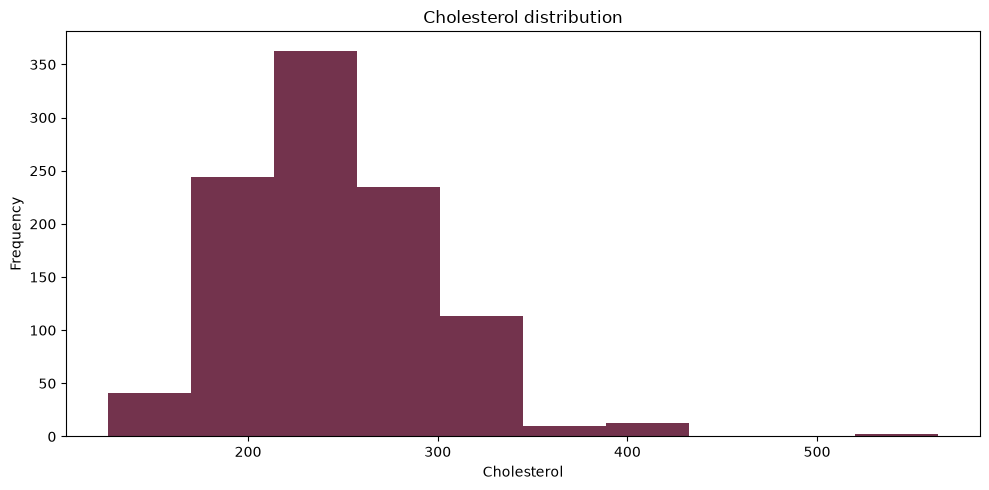

In [130]:
# Plot the cholesterol distribution
if "chol" not in heart_disease_df.columns:
    raise KeyError("Expected a 'chol' column in the source CSV.")

plt.figure(figsize=(10, 5))

heart_disease_df["chol"].plot(
    kind="hist",
    color="#73334d"
)

plt.title("Cholesterol distribution")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### *EXPLORE FURTHER*
**Examine the distributions of several numerical predictors**

We compare histograms for `age`, `trestbps`, `chol`, and `thalach` to notice differences in range, shape, and potentially unusual values. This remains descriptive analysis: omitting missing values for a plot is not the same as imputing them for modeling.

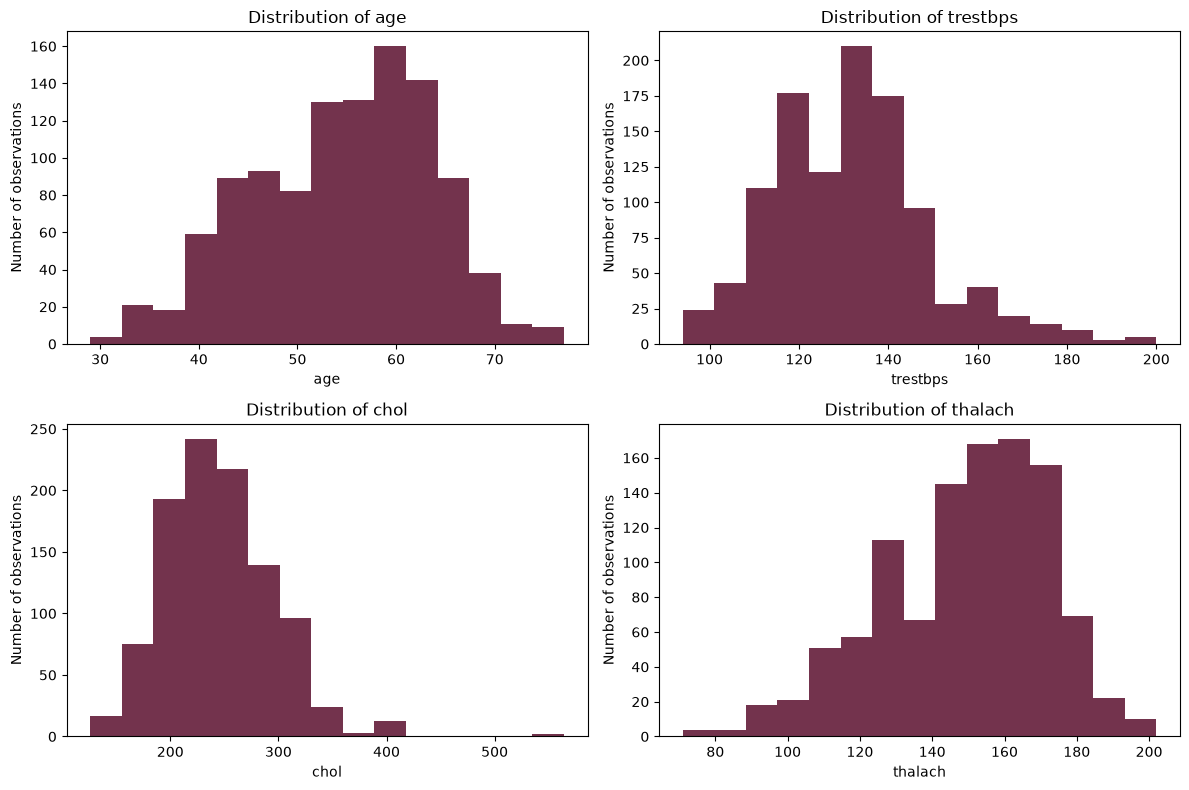

In [131]:
# Compare distributions of continuous predictors
continuous_features = ["age", "trestbps", "chol", "thalach"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for axis, feature in zip(axes.flat, continuous_features):
    heart_disease_df[feature].hist(
        bins=15,
        ax=axis,
        color="#73334d",
        grid=False
    )
    axis.grid(False)
    axis.set_title(f"Distribution of {feature}")
    axis.set_xlabel(feature)
    axis.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

We now move from describing the raw data to preparing it for modeling. We examine missingness and exact duplicate rows, then keep modeling transformations separate from the original observations.

Removing identical records before splitting helps prevent the same row from appearing on both sides of a train–test partition. 

Later, imputers and scalers will learn their parameters only from training data, protecting the held-out test set from preprocessing leakage.

## 5. Remove `oldpeak` and Exact Duplicate Rows

We verified that `oldpeak` is entirely missing. We therefore remove it with `.drop(columns=["oldpeak"])`, which creates a new DataFrame and leaves the source data unchanged. 

The exercise also demonstrates the equivalent `axis="columns"` notation.

We then call `.drop_duplicates()` and reset the index so the cleaned rows have consecutive positions. 

Inspecting the new shape, first rows, and remaining missing-value counts lets us verify each decision before modeling.

> **Caution:** Identical measurements do not necessarily identify the same patient. This exercise removes exact duplicate rows; clinical datasets require additional evidence, ideally patient identifiers, before treating repeated measurements as duplicate individuals.

In [132]:
# Confirm that oldpeak is missing and remove the column on a copy
oldpeak_missing = heart_disease_df["oldpeak"].isna().sum()

print("Missing oldpeak values:\n", oldpeak_missing)
print("\nTotal rows:\n", len(heart_disease_df))
print("\nEntire oldpeak column missing:\n", heart_disease_df["oldpeak"].isna().all())

# Remove the column while preserving the source DataFrame
heart_disease_column_dropped = heart_disease_df.drop(["oldpeak"], axis="columns")

print(
    "\nheart_disease_column_dropped has oldpeak column:\n",
    "oldpeak" in heart_disease_column_dropped.columns.to_list()
)
print(
    "\nheart_disease_df has oldpeak column:\n",
    "oldpeak" in heart_disease_df.columns.to_list()
)

heart_disease_column_dropped = heart_disease_df.drop(columns=["oldpeak"])

print(
    "\nOriginal dimensions (heart_disease_df):\n", 
    heart_disease_df.shape
)
print(
    "\nAfter column removal (heart_disease_column_dropped):\n", 
    heart_disease_column_dropped.shape
)

Missing oldpeak values:
 1076

Total rows:
 1076

Entire oldpeak column missing:
 True

heart_disease_column_dropped has oldpeak column:
 False

heart_disease_df has oldpeak column:
 True

Original dimensions (heart_disease_df):
 (1076, 14)

After column removal (heart_disease_column_dropped):
 (1076, 13)


In [133]:
# Remove exact duplicate rows and inspect the cleaned data
heart_disease_duplicates_dropped = (
    heart_disease_column_dropped.drop_duplicates()
    .reset_index(drop=True) # retains the first instance of each exact row
)

removed_rows = len(heart_disease_column_dropped) - len(heart_disease_duplicates_dropped)

print("Rows removed as duplicates:\n", removed_rows)
print(
    "\nOriginal dimensions (heart_disease_df):\n",
    heart_disease_df.shape
)
print(
    "\nAfter column removal (heart_disease_column_dropped):\n",
    heart_disease_column_dropped.shape
)
print(
    "\nAfter duplicate removal (heart_disease_duplicates_dropped):\n",
    heart_disease_duplicates_dropped.shape
)

# Inspect the resulting rows and unresolved missing values
print("\nCleaned preview:")
print(heart_disease_duplicates_dropped.head())

print(heart_disease_duplicates_dropped.isna().sum())

Rows removed as duplicates:
 638

Original dimensions (heart_disease_df):
 (1076, 14)

After column removal (heart_disease_column_dropped):
 (1076, 13)

After duplicate removal (heart_disease_duplicates_dropped):
 (438, 13)

Cleaned preview:
   age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  slope  ca  \
0   52    1  0.0       125  212.0    0      1.0      168      0      2   2   
1   53    1  0.0       140  203.0    1      0.0      155      1      0   0   
2   70    1  0.0       145  174.0    0      1.0      125      1      0   0   
3   61    1  0.0       148  203.0    0      1.0      161      0      2   1   
4   62    0  0.0       138  294.0    1      1.0      106      0      1   3   

   thal  target  
0     3       0  
1     3       0  
2     3       0  
3     3       0  
4     2       0  
age          0
sex          0
cp          49
trestbps     0
chol        49
fbs          0
restecg     44
thalach      0
exang        0
slope        0
ca           0
thal         0
t

## 6. Calculate the Mean of `restecg`

Imputation replaces missing observations with an explicit estimate or rule. 

For numerical variables, `.mean()` returns the arithmetic average of the non-missing values, which can sometimes serve as an imputation statistic.

Here, however, `restecg` is a categorical measurement encoded numerically. Its mean can fall between valid categories, so we calculate it for illustration rather than as our final modeling strategy. 

We also inspect its observed category frequencies to motivate mode imputation.

In [134]:
# Calculate the numerical mean and examine restecg category counts
mean_value = heart_disease_duplicates_dropped["restecg"].mean()

print("Mean of restecg (demonstration only):\n", mean_value)

print("\nrestecg value counts (including missing values):\n")
print(heart_disease_duplicates_dropped["restecg"].value_counts(dropna=False))

Mean of restecg (demonstration only):
 0.5431472081218274

restecg value counts (including missing values):

restecg
1.0    198
0.0    188
NaN     44
2.0      8
Name: count, dtype: int64


### 6.1. Mean Imputation on a Demonstration Copy

We fill missing `restecg` values with the calculated mean on a copy named `restecg_mean_demo`. 

Comparing the unique values before and after filling exposes why a continuous average may be inappropriate for a categorical predictor.

Assigning `df["column"] = df["column"].fillna(value)` avoids chained-assignment problems associated with some forms of `inplace=True` column updates.

> **Caution:** This is a demonstration only. The mean was calculated before the train–test split. For predictive modeling, we must choose a suitable strategy and learn its replacement values from training data alone.

In [135]:
# Demonstrate why mean imputation can create invalid category values
restecg_mean_demo = heart_disease_duplicates_dropped.copy()

restecg_mean_demo["restecg"] = (
    restecg_mean_demo["restecg"].fillna(mean_value)
)

print(
    "Any missing restecg values AFTER demo imputation?\n",
    restecg_mean_demo["restecg"].isna().any(),
)

print(
    "\nUnique restecg values (BEFORE imputation):\n",
    sorted(heart_disease_duplicates_dropped["restecg"].dropna().unique())
)
print(
    "\nUnique restecg values (AFTER imputation):\n",
    sorted(restecg_mean_demo["restecg"].dropna().unique())
)

Any missing restecg values AFTER demo imputation?
 False

Unique restecg values (BEFORE imputation):
 [np.float64(0.0), np.float64(1.0), np.float64(2.0)]

Unique restecg values (AFTER imputation):
 [np.float64(0.0), np.float64(0.5431472081218274), np.float64(1.0), np.float64(2.0)]


## 7. Define Predictors and Target, Then Split the Data

We separate predictors (`X`) from the diagnosis label (`y`), identify the outcome column, and check class frequencies. 

An 80/20 split reserves observations for held-out evaluation; `random_state=42` makes the partition reproducible.

For this first split, we use `stratify=y` when the class counts and partition sizes make stratification feasible. This helps retain similar target-class proportions in training and test sets. 

We keep `X_train_original` and `X_test_original` as snapshots for comparing later transformations.

We do not impute or scale predictors before splitting. Learning preprocessing statistics from the complete dataset would leak test-set information into model training. 

For grouped or time-ordered records, an entirely different split design may be more appropriate.

In [136]:
# Identify the outcome column and separate features from labels
print(
    "target column exists:\n", 
    'target' in heart_disease_duplicates_dropped.columns
)

# Select the available diagnosis column
TARGET_COLUMN = next(
    (name for name in ("target", "num")
     if name in heart_disease_duplicates_dropped.columns),
    None,
)

if TARGET_COLUMN is None:
    raise KeyError(
        "Could not identify the target column. "
        "Inspect the CSV columns and set TARGET_COLUMN manually "
        "(for example, 'target' or 'num')."
    )

print("Outcome column selected:\n", TARGET_COLUMN)

target column exists:
 True
Outcome column selected:
 target


In [137]:
# Separate predictors
X = heart_disease_duplicates_dropped.drop(columns=[TARGET_COLUMN])

print(X)

     age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  slope  ca  \
0     52    1  0.0       125  212.0    0      1.0      168      0      2   2   
1     53    1  0.0       140  203.0    1      0.0      155      1      0   0   
2     70    1  0.0       145  174.0    0      1.0      125      1      0   0   
3     61    1  0.0       148  203.0    0      1.0      161      0      2   1   
4     62    0  0.0       138  294.0    1      1.0      106      0      1   3   
..   ...  ...  ...       ...    ...  ...      ...      ...    ...    ...  ..   
433   54    1  0.0       120  188.0    0      1.0      113      0      1   1   
434   58    1  2.0       140    NaN    1      0.0      165      0      2   0   
435   45    1  1.0       128    NaN    0      0.0      170      0      2   0   
436   58    1  0.0       114    NaN    0      2.0      140      0      0   3   
437   58    1  0.0       128  216.0    0      0.0      131      1      1   3   

     thal  
0       3  
1       3  
2  

In [138]:
# Separate the diagnosis label
y = heart_disease_duplicates_dropped[TARGET_COLUMN]

print(y)

0      0
1      0
2      0
3      0
4      0
      ..
433    0
434    1
435    1
436    0
437    0
Name: target, Length: 438, dtype: int64


In [139]:
# Check class balance and determine whether stratification is feasible
if y.isna().any():
    raise ValueError("Target contains missing values; resolve them before splitting.")

class_counts = y.value_counts(dropna=False)

print(class_counts)

n_classes = len(class_counts)

n_train = int(np.floor(0.80 * len(y)))
n_test = int(np.ceil(0.20 * len(y)))

# Check the minimum class and partition-size requirements
stratification_checks = {
    "At least two distinct target classes": n_classes > 1,
    "At least two observations per class": class_counts.min() >= 2,
    "Enough test observations for every class": n_test >= n_classes,
    "Enough training observations for every class": n_train >= n_classes,
}

can_stratify = all(stratification_checks.values())

print("\nSTRATIFIED TRAIN-TEST SPLIT (80/20)")
print(f"-Total observations: {len(y)}")
print(f"-Target classes: {n_classes}")
print(f"-Smallest class: {class_counts.min()} observations")
print(f"-Training observations: {n_train}")
print(f"-Testing observations: {n_test}")

print("\nStratification requirements:")

for criterion, satisfied in stratification_checks.items():
    status = "PASS" if satisfied else "FAIL"
    print(f"  [{status}] {criterion}")

print(
    "\nConclusion: \n"
    + (
        "  [YOU'RE GOOD TO GO!] Stratified splitting is feasible"
        if can_stratify
        else "Stratified splitting is not feasible"
    )
)

target
1    230
0    208
Name: count, dtype: int64

STRATIFIED TRAIN-TEST SPLIT (80/20)
-Total observations: 438
-Target classes: 2
-Smallest class: 208 observations
-Training observations: 350
-Testing observations: 88

Stratification requirements:
  [PASS] At least two distinct target classes
  [PASS] At least two observations per class
  [PASS] Enough test observations for every class
  [PASS] Enough training observations for every class

Conclusion: 
  [YOU'RE GOOD TO GO!] Stratified splitting is feasible


In [140]:
# Record incomplete predictors before partitioning
missing_counts = X.isna().sum()

print(missing_counts[missing_counts > 0])

cp         49
chol       49
restecg    44
dtype: int64


In [141]:
# Split the original data and compare class proportions
# Keep a reproducible partition and unmodified copies
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y if can_stratify else None,
)

X_train_original = X_train.copy()
X_test_original = X_test.copy()

print("Stratified split used:\n", can_stratify)
print("\nX_train shape:\n", X_train.shape)
print("\nX_test shape:\n", X_test.shape)
print("\ny_train shape:\n", y_train.shape)
print("\ny_test shape:\n", y_test.shape)

Stratified split used:
 True

X_train shape:
 (350, 12)

X_test shape:
 (88, 12)

y_train shape:
 (350,)

y_test shape:
 (88,)


In [142]:
# Compare original, training, and test class shares
class_proportions = y.value_counts(normalize=True)

print("\nOriginal target proportions:\n")
print(class_proportions)

print("\nTRAINING target proportions:\n")
print(y_train.value_counts(normalize=True))

print("\nTESTING target proportions:\n")
print(y_test.value_counts(normalize=True))


Original target proportions:

target
1    0.525114
0    0.474886
Name: proportion, dtype: float64

TRAINING target proportions:

target
1    0.525714
0    0.474286
Name: proportion, dtype: float64

TESTING target proportions:

target
1    0.522727
0    0.477273
Name: proportion, dtype: float64


### *EXPLORE FURTHER*
**Compare numerical measurements across target classes**

We group the cleaned observations by target class and summarize the mean `age`, `trestbps`, `chol`, and `thalach` for each group. These descriptive summaries are not used to choose predictors or fit models; they simply illustrate how outcome groups can differ in the observed sample.

In [143]:
# Summarize numerical predictors by observed outcome class
comparison_features = ["age", "trestbps", "chol", "thalach"]

class_feature_means = (
    heart_disease_duplicates_dropped
    .groupby(TARGET_COLUMN)[comparison_features]
    .mean()
    .round(1)
)

print("Mean measurements by observed target class:\n")
print(class_feature_means)

print("\nObservations by target class:\n")
print(heart_disease_duplicates_dropped[TARGET_COLUMN].value_counts().sort_index())

Mean measurements by observed target class:

         age  trestbps   chol  thalach
target                                
0       56.4     134.2  251.8    137.8
1       52.8     129.7  242.6    158.0

Observations by target class:

target
0    208
1    230
Name: count, dtype: int64


In [144]:
# Compare missing-value counts in each partition
missing_counts_train = X_train.isna().sum()

print("X_train missing data:\n")
print(missing_counts_train[missing_counts_train > 0])

missing_counts_test = X_test.isna().sum()

print("\nX_test missing data:\n")
print(missing_counts_test[missing_counts_test > 0])

X_train missing data:

cp         37
chol       38
restecg    32
dtype: int64

X_test missing data:

cp         12
chol       11
restecg    12
dtype: int64


## 8. Impute `restecg` Without Data Leakage

Because `restecg` contains numerical codes for categories, we choose `SimpleImputer(strategy="most_frequent")` rather than the earlier mean. 

We fit on `X_train_original` and apply the same learned replacement category to `X_test_original` with `.transform()`.

We work with copies so the original train/test partitions remain available. 

The checks first confirm that `restecg` has no missing values, then show which other columns still require attention. 

Imputation supplies a practical replacement, not proof of a patient's true category.

During cross-validation, imputation must be fitted again within each training fold. We will show that pattern later using a pipeline.

In [145]:
# Fit the categorical imputer on training data and transform the test set
X_train_imputed = X_train_original.copy()
X_test_imputed = X_test_original.copy()

restecg_imputer = SimpleImputer(strategy="most_frequent")

X_train_imputed["restecg"] = restecg_imputer.fit_transform(
    X_train_original[["restecg"]]
).ravel()

print(X_train_imputed["restecg"])

130    0.0
245    0.0
157    0.0
16     0.0
339    0.0
      ... 
252    1.0
100    0.0
319    1.0
66     0.0
294    0.0
Name: restecg, Length: 350, dtype: float64


In [146]:
# Apply the learned category to held-out records without refitting
X_test_imputed["restecg"] = restecg_imputer.transform(
    X_test_original[["restecg"]]
).ravel()

print(X_test_imputed["restecg"])

83     1.0
25     1.0
420    0.0
177    1.0
68     0.0
      ... 
341    1.0
380    0.0
1      0.0
142    1.0
332    1.0
Name: restecg, Length: 88, dtype: float64


In [147]:
# Verify the imputed category and inspect remaining missing values
print("Training-derived replacement category:\n", restecg_imputer.statistics_[0])

print("\nRemaining missing restecg values in training:\n",
      X_train_imputed["restecg"].isna().sum())

print("\nRemaining missing restecg values in testing:\n",
      X_test_imputed["restecg"].isna().sum())


Training-derived replacement category:
 1.0

Remaining missing restecg values in training:
 0

Remaining missing restecg values in testing:
 0


In [148]:
# Inspect other columns that still need imputation
print("Missing values in TRAINING features after restecg imputation:\n")
print(X_train_imputed.isna().sum()[X_train_imputed.isna().sum() > 0])

print("\nMissing values in TESTING features after restecg imputation:\n")
print(X_test_imputed.isna().sum()[X_test_imputed.isna().sum() > 0])

Missing values in TRAINING features after restecg imputation:

cp      37
chol    38
dtype: int64

Missing values in TESTING features after restecg imputation:

cp      12
chol    11
dtype: int64


## 9. Original `age` Distribution in the Training Set

We plot training-set ages before scaling. This is the reference distribution for the next two demonstrations. 

pandas `.dropna()` removes missing values only from this visualization; it does not alter `X_train_original`.

If age were missing during model fitting, we would need a training-fitted imputer before scaling.

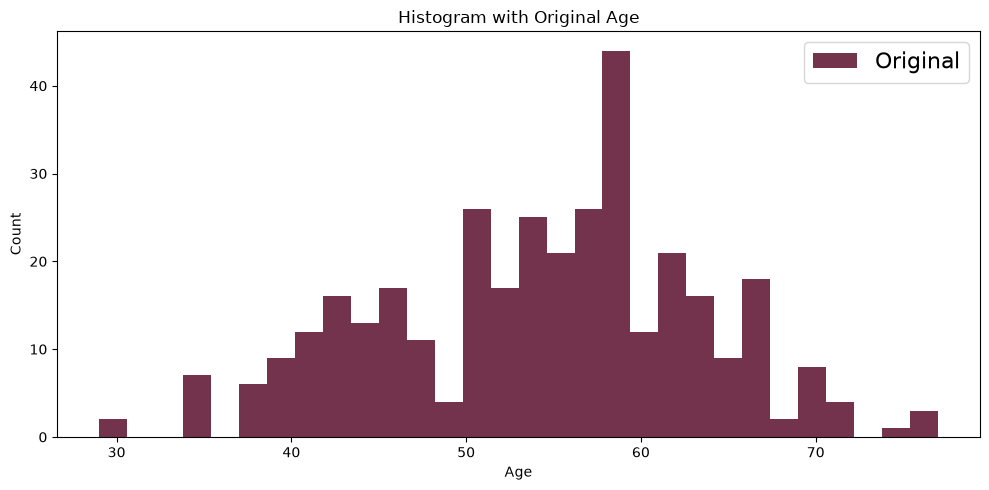

In [149]:
# Plot unscaled training ages as a baseline for scaling
age = X_train_original["age"].dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    age,
    color="#73334d",
    bins=30,
    label="Original"
)

plt.legend(prop={"size": 16})
plt.title("Histogram with Original Age")
plt.xlabel("Age")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

## 10. Min–Max Normalization of `age`

`MinMaxScaler` converts training ages to the default interval from 0 to 1:

$$
x_{\mathrm{scaled}} = \frac{x-x_{\min,\mathrm{train}}}{x_{\max,\mathrm{train}}-x_{\min,\mathrm{train}}}
$$

We fit the scaler on training ages using `fit_transform()` and reuse those same limits for test ages with `transform()`. 

Test values outside the training range may be transformed below 0 or above 1.

Copies named `X_train_normalized` and `X_test_normalized` preserve the original data. 

Scikit-learn expects a two-dimensional input array; `.reshape(-1, 1)` supplies it, and `.ravel()` returns a one-dimensional result for assignment to a DataFrame column.

In [150]:
# Normalize age using only training-set minimum and maximum
X_train_normalized = X_train_imputed.copy()
X_test_normalized = X_test_imputed.copy()

if X_train_normalized["age"].isna().any() or X_test_normalized["age"].isna().any():
    raise ValueError("Missing age values: impute age using training data before scaling.")

normalizer = MinMaxScaler()

# Fit the minimum and maximum on training ages
X_train_normalized["age"] = normalizer.fit_transform(
    X_train_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_train_normalized["age"])

130    0.208333
245    0.645833
157    0.333333
16     0.458333
339    0.500000
         ...   
252    0.687500
100    0.500000
319    0.520833
66     0.625000
294    0.250000
Name: age, Length: 350, dtype: float64


In [151]:
# Transform test ages with unchanged scaling parameters
X_test_normalized["age"] = normalizer.transform(
    X_test_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_test_normalized["age"])

83     0.687500
25     0.666667
420    0.520833
177    0.416667
68     0.562500
         ...   
341    0.520833
380    0.541667
1      0.500000
142    0.583333
332    0.479167
Name: age, Length: 88, dtype: float64


In [152]:
# Compare
print(
    "TRAINING minimum age:\n", 
    normalizer.data_min_[0]
)
print(
    "\nTRAINING maximum age:\n", 
    normalizer.data_max_[0]
)

print(
    "\nNormalized TRAINING range:\n",
    (X_train_normalized["age"].min(), X_train_normalized["age"].max())
)
print(
    "\nNormalized TESTING range:\n",
    (X_test_normalized["age"].min(), X_test_normalized["age"].max())
)

TRAINING minimum age:
 29.0

TRAINING maximum age:
 77.0

Normalized TRAINING range:
 (np.float64(0.0), np.float64(0.9999999999999999))

Normalized TESTING range:
 (np.float64(0.10416666666666663), np.float64(0.8749999999999999))


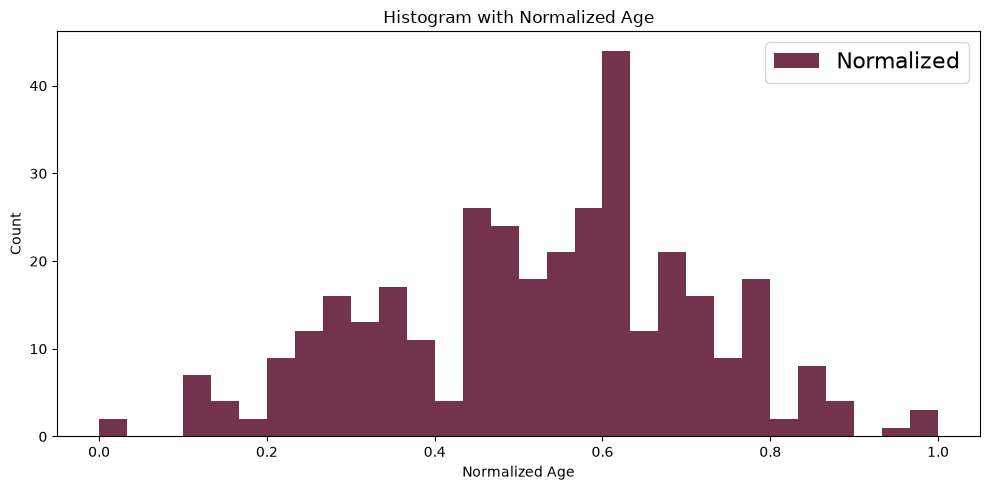

In [153]:
# Plot the normalized training-age distribution
plt.figure(figsize=(10, 5))

plt.hist(
    X_train_normalized["age"],
    bins=30,
    color="#73334d",

    label="Normalized"
)

plt.legend(prop={"size": 16})
plt.title("Histogram with Normalized Age")
plt.xlabel("Normalized Age")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

## 11. Z-Score Standardization of `age`

`StandardScaler` centers training ages around zero and scales by their training-set standard deviation:

$$
z = \frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

We fit on the original, imputed training ages—not on the min–max-normalized values—and reuse the training parameters for the test set. 

Scikit-learn uses the population standard deviation (`ddof=0`), so standardized training ages have mean near 0 and population standard deviation near 1.

Standardization changes the scale, not the shape of a distribution; it does not make a skewed variable normally distributed.

In [154]:
# Standardize age using training-set mean and standard deviation
X_train_standardized = X_train_imputed.copy()
X_test_standardized = X_test_imputed.copy()

standardizer = StandardScaler()

# Fit the mean and standard deviation on training ages
X_train_standardized["age"] = standardizer.fit_transform(
    X_train_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_train_standardized["age"])

130   -1.681613
245    0.641232
157   -1.017943
16    -0.354273
339   -0.133050
         ...   
252    0.862455
100   -0.133050
319   -0.022438
66     0.530620
294   -1.460390
Name: age, Length: 350, dtype: float64


In [155]:
# Reuse those parameters for held-out test ages
X_test_standardized["age"] = standardizer.transform(
    X_test_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_test_standardized["age"])

83     0.862455
25     0.751843
420   -0.022438
177   -0.575497
68     0.198785
         ...   
341   -0.022438
380    0.088173
1     -0.133050
142    0.309397
332   -0.243662
Name: age, Length: 88, dtype: float64


In [156]:
# Compare
print(
    "TRAINING mean age:\n", 
    standardizer.mean_[0]
)
print(
    "\nTRAINING population std. dev.:\n",
    standardizer.scale_[0]
)

print(
    "\nStandardized TRAINING mean age:\n",
    f'{X_train_standardized["age"].mean():.4f}'
)
print(
    "\nStandardized TRAINING population std. dev.:\n",
    X_train_standardized["age"].std(ddof=0)
)

TRAINING mean age:
 54.20285714285714

TRAINING population std. dev.:
 9.040637958345503

Standardized TRAINING mean age:
 0.0000

Standardized TRAINING population std. dev.:
 1.0


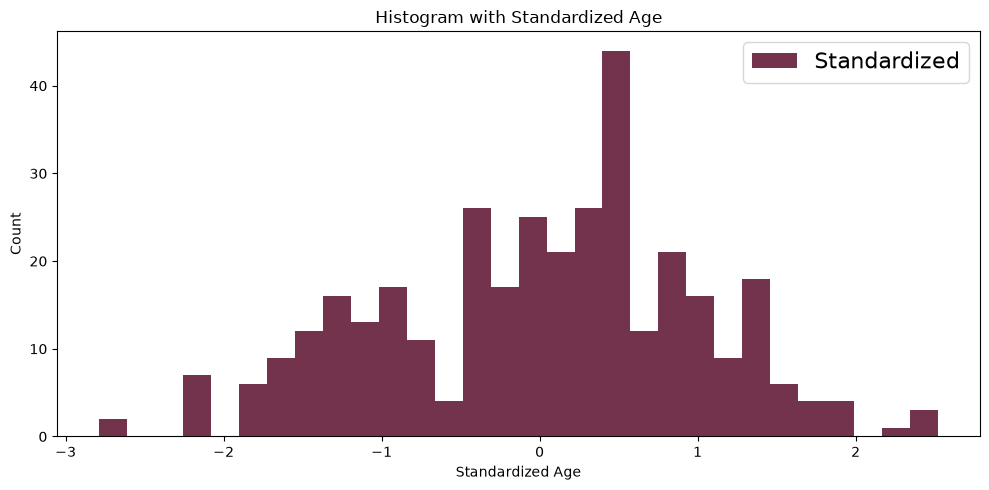

In [157]:
# Plot standardized ages distribution
plt.figure(figsize=(10, 5))

plt.hist(
    X_train_standardized["age"],
    bins=30,
    color="#73334d",

    label="Standardized"
)

plt.legend(prop={"size": 16})
plt.title("Histogram with Standardized Age")
plt.xlabel("Standardized Age")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

## 12. Compare Results and Validate Assumptions

We compare the original, normalized, and standardized training ages in one table. 

The values remain in the same order because both scaling methods are linear transformations; their means, ranges, and standard deviations differ.

Assertions verify that age was not changed during imputation, the expected training-scale properties hold, and the training and test feature schemas match. 

Recall that pandas `.std()` defaults to a sample standard deviation (`ddof=1`), unlike `StandardScaler`.

These exercises scale only `age`. A production-ready estimator must also handle missingness and appropriate encoding or scaling for other features. Later we use `Pipeline` and `ColumnTransformer` to do this within cross-validation.

In [158]:
# Compare age values across the three preprocessing scales
summary = pd.DataFrame({
    "original": X_train_original["age"],
    "normalized": X_train_normalized["age"],
    "standardized": X_train_standardized["age"],
}).agg(["count", "mean", "std", "min", "max"])

print("Training age summary (pandas std uses ddof=1):\n")
print(summary.to_string(float_format=lambda value: f"{value:.4f}"))

Training age summary (pandas std uses ddof=1):

       original  normalized  standardized
count  350.0000    350.0000      350.0000
mean    54.2029      0.5251        0.0000
std      9.0536      0.1886        1.0014
min     29.0000      0.0000       -2.7877
max     77.0000      1.0000        2.5216


In [159]:
# Validate scaling assumptions and preserved feature schemas
assert X_train_original["age"].equals(X_train_imputed["age"]), (
    "Age values changed during imputation"
)

assert np.isclose(X_train_standardized["age"].mean(), 0.0, atol=1e-10), (
    "Standardized training ages do not have approximately zero mean"
)

assert np.isclose(X_train_standardized["age"].std(ddof=0), 1.0, atol=1e-10), (
    "Standardized training ages do not have unit population variance"
)

assert X_train_normalized["age"].between(0, 1).all(), (
    "Normalized training ages contain values outside [0, 1]"
)

assert np.isclose(X_train_normalized["age"].min(), 0.0), (
    "Normalized training minimum is not approximately zero"
)

assert np.isclose(X_train_normalized["age"].max(), 1.0), (
    "Normalized training maximum is not approximately one"
)

assert X_train_original.columns.equals(X_test_original.columns), (
    "Training and test predictor columns do not match"
)

print("\nAll data integrity and feature scaling checks passed")


All data integrity and feature scaling checks passed


## 13. Quick Reference: pandas and scikit-learn Methods

The following operations recur throughout the notebook. The distinction between attributes, printing methods, fitted transformers, and transformations is especially important.

| Expression | Meaning |
|---|---|
| `df.head()` | Preview the first five rows by default |
| `df.info()` | Print schema, non-null counts, dtypes, and memory use; returns `None` |
| `df.shape` | Return `(rows, columns)` without parentheses |
| `df["sex"].count()` | Count non-missing entries |
| `df["sex"].value_counts()` | Count observations by category |
| `df["sex"].value_counts(dropna=False)` | Include missing values in the category counts |
| `df["restecg"].mean()` | Average non-missing numerical values |
| `df["restecg"].fillna(value)` | Return a Series with missing entries filled |
| `df.drop(columns=["oldpeak"])` | Remove the named column |
| `df.dropna(axis="columns", how="all")` | Remove columns that are entirely missing |
| `df.drop_duplicates()` | Remove exact duplicate rows |
| `df["age"].isna().any()` | Check whether any ages are missing |
| `train_test_split(...)` | Partition aligned predictors and labels |
| `scaler.fit_transform(X_train)` | Learn training parameters and transform training data |
| `scaler.transform(X_test)` | Reuse learned parameters on test data |
| `.reshape(-1, 1)` | Convert a one-dimensional array to a single-feature matrix |
| `.ravel()` | Flatten a single-column array for assignment |

### Preparation checklist

- We loaded the intended local CSV without downloading substitutes
- We inspected missing values and duplicates before cleaning
- We preserved original partitions and fit transformations on training data
- We kept min–max normalization and z-score standardization separate
- We used descriptive histograms without drawing clinical conclusions

Next, we use the prepared predictors to demonstrate model-based feature selection.

The next exercise introduces a random forest as a feature selector rather than as the classifier evaluated later. Impurity-based importance indicates which features the forest used to reduce node impurity; it does not establish causal influence. We will fit feature selection using training observations only and apply the resulting mask to test observations.

## 14. Random Forest: Model-Based Feature Selection

**Exercise.** Fit `RandomForestClassifier()` with `n_jobs=-1`, `class_weight="balanced"`, and `max_depth=5`, and use `SelectFromModel` to keep predictors meeting its default importance threshold. The notebook also specifies `random_state=42` to make feature rankings reproducible.

Important considerations:

- We use copies of the earlier `X_train_imputed` and `X_test_imputed` partitions. 

- Random forests generally do not require feature standardization, but their inputs must be numeric and free of missing values. 

- Because only `restecg` was imputed in Section 8, we finish imputing `cp` (mode) and `chol` (median) before fitting the forest.

- The resulting importance scores may favor variables with more available split points and may be unstable among correlated predictors. 

- The selector is fitted on training data only; the test set receives the same columns without refitting.

### 14.1. Diagnose and Complete Missing-Value Imputation

First, we count remaining missing values in each partition. 

We copy those partitions before filling `cp` with the training-set mode and `chol` with the training-set median. 

We keep the learned statistics visible and assert that the forest's inputs contain no missing values.

In [160]:
# Identify remaining missing values before forest feature selection
missing_train = (
    X_train_imputed.isna()
    .sum()
    .loc[lambda counts: counts > 0]
)

missing_test = (
    X_test_imputed.isna()
    .sum()
    .loc[lambda counts: counts > 0]
)

print("Missing values in TRAINING data:\n")
print(missing_train)

print("\nMissing values in TESTING data:\n")
print(missing_test)

Missing values in TRAINING data:

cp      37
chol    38
dtype: int64

Missing values in TESTING data:

cp      12
chol    11
dtype: int64


In [161]:
# Copy partitions and fit feature-specific imputers on training data
from sklearn.impute import SimpleImputer

X_train_rf = X_train_imputed.copy()
X_test_rf = X_test_imputed.copy()

# Impute categorical chest-pain codes with the training mode
cp_imputer = SimpleImputer(strategy="most_frequent")

X_train_rf["cp"] = cp_imputer.fit_transform(
    X_train_rf[["cp"]]
).ravel()

X_test_rf["cp"] = cp_imputer.transform(
    X_test_rf[["cp"]]
).ravel()

# Impute continuous cholesterol values with the training median
chol_imputer = SimpleImputer(strategy="median")

X_train_rf["chol"] = chol_imputer.fit_transform(
    X_train_rf[["chol"]]
).ravel()

X_test_rf["chol"] = chol_imputer.transform(
    X_test_rf[["chol"]]
).ravel()

In [162]:
# Inspect learned replacement values
print("Training-derived replacement values:\n")

print(
    "Most frequent chest pain category (cp):\n",
    cp_imputer.statistics_[0]
)

print(
    "\nMedian serum cholesterol (chol):\n",
    chol_imputer.statistics_[0]
)

Training-derived replacement values:

Most frequent chest pain category (cp):
 0.0

Median serum cholesterol (chol):
 240.0


In [163]:
# Validate that all missing values have been imputed
print(
    "Remaining missing values in training (X_train_rf):\n",
    X_train_rf.isna().sum().sum()
)

print(
    "\nRemaining missing values in testing (X_test_rf):\n",
    X_test_rf.isna().sum().sum()
)

# Assert complete imputation
# Reject incomplete data before model fitting
assert not X_train_rf.isna().any().any(), (
    "Training data still contain missing values."
)

assert not X_test_rf.isna().any().any(), (
    "Testing data still contain missing values."
)

Remaining missing values in training (X_train_rf):
 0

Remaining missing values in testing (X_test_rf):
 0


### 14.2. Fit the Random Forest

We fit the class-balanced forest to training data only. `n_jobs=-1` makes eligible operations parallel, `max_depth=5` limits each tree's depth, and `random_state=42` makes it reproducible. 

The forest's feature-importance vector will supply the thresholding scores in the next step.

In [164]:
# Fit a reproducible, class-balanced random forest on training rows
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

rf = RandomForestClassifier(
    n_jobs=-1,
    class_weight="balanced",
    max_depth=5,
    random_state=42,
)

rf.fit(X_train_rf, y_train)

print(
    "Random forest fitted on",
    X_train_rf.shape[0],
    "training rows."
)

Random forest fitted on 350 training rows.


### 14.3. Apply the Learned Feature-Selection Mask

We pass the fitted random forest to `SelectFromModel(rf, prefit=True)`. For this estimator, the default threshold is the mean feature importance. 

`get_support()` yields a Boolean mask over the original feature columns.

`transform()` uses that mask to retain exactly the same predictors in the training and test partitions. 

We convert the DataFrames to NumPy arrays for this exercise, so we recover feature names separately from the original column index. Both partitions must have identical column ordering.

In [165]:
# Select features using the fitted forest and apply the same mask
feature_selector = SelectFromModel(rf, prefit=True)

# Apply one fitted mask to both partitions
X_train_transformed = feature_selector.transform(
    X_train_rf.to_numpy()
)

X_test_transformed = feature_selector.transform(
    X_test_rf.to_numpy()
)

# Recover the mask and the corresponding feature names
features_bool = feature_selector.get_support()

selected_features = X_train_rf.columns[features_bool]

print(f"\nSelected features:\n {selected_features}")

print("\nOriginal TRAINING shape:\n", X_train_rf.shape)

print("\nSelected TRAINING shape:\n", X_train_transformed.shape)

print("\nSelected TESTING shape:\n", X_test_transformed.shape)

assert X_train_transformed.shape[1] == X_test_transformed.shape[1]
assert X_train_transformed.shape[1] == len(selected_features)


Selected features:
 Index(['cp', 'thalach', 'ca', 'thal'], dtype='str')

Original TRAINING shape:
 (350, 12)

Selected TRAINING shape:
 (350, 4)

Selected TESTING shape:
 (88, 4)


### 14.4. Visualize Selected Feature Importances

We align `selected_features` with `rf.feature_importances_[features_bool]` and display a horizontal bar chart. 

The bars describe impurity reduction within this trained forest; they should not be interpreted as effect sizes or causal claims.

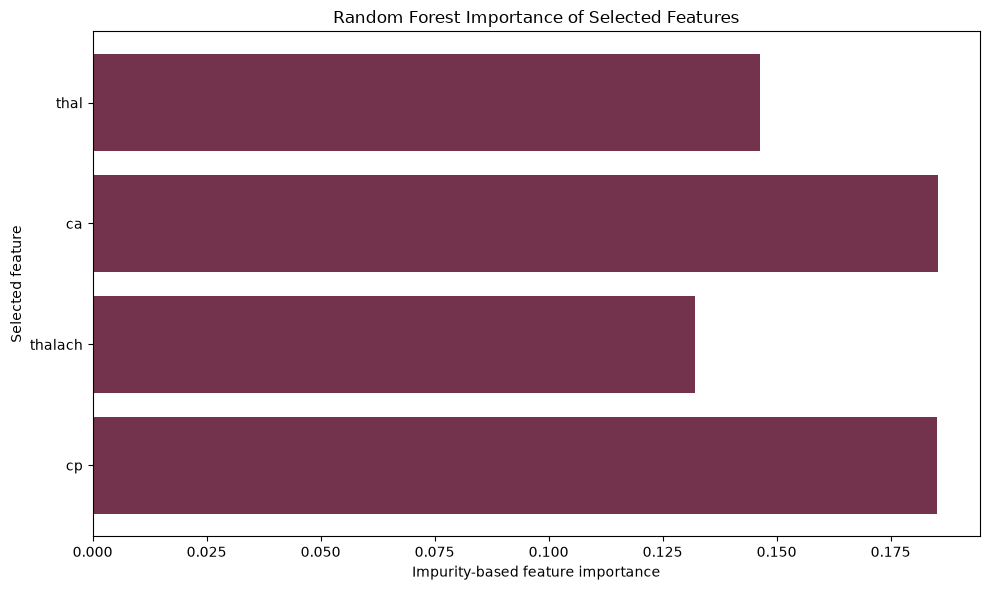

In [166]:
# Plot selected random forest feature importances
# Align selected predictor names with their fitted forest importances
feature_importance = pd.DataFrame({
    "feature": selected_features,
    "importance": rf.feature_importances_[features_bool],
})

# Plot importance scores without treating them as causal effects
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["feature"],
    feature_importance["importance"],
    color="#73334d",
)
plt.title("Random Forest Importance of Selected Features")
plt.xlabel("Impurity-based feature importance")
plt.ylabel("Selected feature")
plt.tight_layout()
plt.show()

## 15. Support Vector Classification: Required Imports

**Exercise.** Import `train_test_split` from `sklearn.model_selection` and `SVC` from `sklearn.svm`. Importing these tools does not create a new partition or fit a model.

A linear support vector classifier learns a separating hyperplane. Unlike a random forest, it can be sensitive to feature scales, so standardization is often useful. 

Our subsequent exercise retains the unstratified split and imputes missing features without silently changing the prescribed SVC specification.

In [167]:
# Import the splitter and support vector classifier
from sklearn.model_selection import train_test_split

from sklearn.svm import SVC

## 16. Create a New Unstratified 80/20 Split for SVC

**Exercise.** Use `train_test_split(heart_disease_X, heart_disease_y, test_size=0.2, random_state=42)` without `stratify`. 

We alias the existing `X` and `y` to the exercise's names, inspect their shapes and missingness, and create a new partition.

This operation deliberately reassigns `X_train`, `X_test`, `y_train`, and `y_test`. It does not modify snapshots from the earlier stratified split. 

From here, the SVC and logistic-regression comparisons use the new, unstratified held-out partition. 

Statistics learned from the earlier partition must not be reused on this new training sample.

In [168]:
# Inspect predictor and target shapes
print("X:\n", X.shape)
print("y:\n", y.shape)

# Inspect the type of the target variable to ensure it's a pandas Series
print("\ntarget type:\n", type(y))

X:
 (438, 12)
y:
 (438,)

target type:
 <class 'pandas.Series'>


In [169]:
# Inspect missing values
print(
    "Missing values in target (y):\n", 
    y.isna().sum()
)

missing_counts = X.isna().sum()

print("\nMissing values in predictors (X):\n")
print(missing_counts[missing_counts > 0])

Missing values in target (y):
 0

Missing values in predictors (X):

cp         49
chol       49
restecg    44
dtype: int64


In [170]:
# Create the unstratified exercise-specific 80/20 split
heart_disease_X = X
heart_disease_y = y

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(
    heart_disease_X,
    heart_disease_y,
    test_size=0.20,
    random_state=42,
)

print("TRAINING feature shape (X_train):\n", X_train.shape)
print("\nTESTING feature shape (X_test):\n", X_test.shape)
print("\nTRAINING labels shape (y_train):\n", y_train.shape)
print("\nTESTING labels shape (y_test):\n", y_test.shape)

TRAINING feature shape (X_train):
 (350, 12)

TESTING feature shape (X_test):
 (88, 12)

TRAINING labels shape (y_train):
 (350,)

TESTING labels shape (y_test):
 (88,)


## 17. Fit a Linear Support Vector Classifier and Predict

**Exercise.** Create `svc_model = SVC(kernel="linear")`, fit it on the training observations, and predict labels for the corresponding held-out observations. The kernel is linear and `C` keeps its default value of 1.0.

Because the actual CSV has missing values, we first fit separate imputers on this exercise's training split: most-frequent imputation for categorical `cp` and `restecg`, and median imputation for continuous `chol`. 

We apply the learned replacements to the test set and check that no missing values remain. This adapts the exercise's raw `fit(X_train, y_train)` and `predict(X_test)` statements to the dataset without changing their modeling intent.

`svc_y_pred` contains class labels, not performance scores. This SVC uses imputed predictors without scaling; linear SVC often benefits from scaling, so subsequent comparisons describe complete procedures rather than isolating the effect of the algorithm.

In [171]:
# Prepare numeric training and test features with training-fitted imputers
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train.dtypes):
    raise TypeError(
        "SVC training features contain nonnumeric columns. "
        "Encode these predictors using training-fitted preprocessing."
    )

X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()

# Specify categorical and continuous imputation groups
categorical_columns = ["cp", "restecg"]

numerical_columns = ["chol"]

categorical_imputer = SimpleImputer(
    strategy="most_frequent"
)

numerical_imputer = SimpleImputer(
    strategy="median"
)

# Fit category replacements only on training rows
X_train_imputed[categorical_columns] = categorical_imputer.fit_transform(
    X_train[categorical_columns]
)

X_test_imputed[categorical_columns] = categorical_imputer.transform(
    X_test[categorical_columns]
)

# Fit the cholesterol median only on training rows
X_train_imputed[numerical_columns] = numerical_imputer.fit_transform(
    X_train[numerical_columns]
)

X_test_imputed[numerical_columns] = numerical_imputer.transform(
    X_test[numerical_columns]
)

In [172]:
# Verify learned imputation statistics
print(
    "\nTraining-derived categorical replacement values:\n",
    dict(zip(categorical_columns, categorical_imputer.statistics_))
)

print(
    "\nTraining-derived numerical replacement values:\n",
    dict(zip(numerical_columns, numerical_imputer.statistics_))
)


Training-derived categorical replacement values:
 {'cp': np.float64(0.0), 'restecg': np.float64(1.0)}

Training-derived numerical replacement values:
 {'chol': np.float64(243.0)}


In [173]:
# Check for missing values
train_missing = X_train_imputed.isna().sum()
test_missing = X_test_imputed.isna().sum()

train_missing = train_missing[train_missing > 0]
test_missing = test_missing[test_missing > 0]

print(
    "\nRemaining missing values in TRAINING:\n",
    train_missing if not train_missing.empty else "None"
)

print(
    "\nRemaining missing values in TESTING:\n",
    test_missing if not test_missing.empty else "None"
)

if not train_missing.empty or not test_missing.empty:
    raise ValueError(
        "Missing values remain after imputation. "
        "Inspect the affected features before fitting the SVC."
    )


Remaining missing values in TRAINING:
 None

Remaining missing values in TESTING:
 None


In [174]:
# Fit the linear support vector classifier and predict held-out labels
svc_model = SVC(kernel="linear")

svc_model.fit(X_train_imputed, y_train)

svc_y_pred = svc_model.predict(X_test_imputed)

print(
    "Predicted test labels:\n", 
    svc_y_pred
)

Predicted test labels:
 [0 1 1 0 0 1 1 1 0 1 0 0 1 1 0 0 0 1 0 0 0 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1
 0 0 1 0 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 0 1 1 1 1 0 1 0 1 0 0 1 0 0 0
 1 1 1 1 0 1 0 1 0 1 0 1 0 0]


We next distinguish three questions:

- How does a fitted classifier predict held-out labels?
- How do different models compare on the same test partition?
- How does cross-validation estimate performance across new training/validation folds?

MLflow records fitted model parameters and experiment metadata; it does not train the classifier when we log a run. 

Our linear SVC and logistic regression (see below) also use different preprocessing, so their comparison concerns complete modeling procedures, not algorithms alone.

## 18. Fit Logistic Regression and Track Coefficients with MLflow

**Exercise.** Fit a logistic-regression classifier, then select the MLflow experiment `Logistic Regression Heart Disease Prediction`, start a run, log coefficients as `coef_0`, `coef_1`, and so on, log the intercept, and print the run ID.

We standardize the imputed SVC exercise's training features with `StandardScaler`, apply the same transformation to the test features, and fit `LogisticRegression(max_iter=1000, random_state=42)`. 

A deep copy, `tracked_logistic_model`, makes the estimator logged in MLflow explicit and avoids confusion with the earlier feature selector.

`coef_` and `intercept_` are learned parameters rather than hyperparameters, even though this exercise requests `mlflow.log_param()` rather than `log_metric()` or an artifact. 

MLflow is an optional external dependency and may create local tracking files when the logging cell runs. No run is initiated merely by saving the notebook.

In [175]:
# Fit a standardized logistic regression and predict test labels
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler on the training observations only
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Fit a logistic classifier independently of the SVC
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_y_pred = logistic_model.predict(X_test_scaled)

print(
    "Predicted test labels:\n",
    logistic_y_pred
)

Predicted test labels:
 [0 1 1 0 0 1 1 1 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1 1
 0 0 1 0 0 0 1 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 0 1 1 1 1 0 1 0 1 0 0 1 0 0 0
 1 1 1 0 0 1 0 1 0 1 0 1 0 0]


In [176]:
# Report the test accuracy of the logistic regression model
accuracy = logistic_model.score(X_test_scaled, y_test)

print(f"\nTest accuracy: {accuracy:.2%}")


Test accuracy: 82.95%


In [177]:
# Import Python's copy module for creating independent object copies
import copy

# Inspect the type of the original fitted logistic regression model
print("Original model type:\n", type(logistic_model))

# Create a deep copy that preserves the fitted parameters and learned attributes
# Changes to the copied model will not modify the original model
tracked_logistic_model = copy.deepcopy(logistic_model)

# Verify that the copied model retains the same estimator type
print("\nCopied model type:\n", type(tracked_logistic_model))

Original model type:
 <class 'sklearn.linear_model._logistic.LogisticRegression'>

Copied model type:
 <class 'sklearn.linear_model._logistic.LogisticRegression'>


In [178]:
# Import MLflow to confirm that the package is installed and accessible
import mlflow

# Display the installed MLflow version for reproducibility
print("MLflow version:", mlflow.__version__)

MLflow version: 3.18.0


In [179]:
# Log fitted logistic-regression coefficients in an MLflow run
from sklearn.linear_model import LogisticRegression
from sklearn.utils.validation import check_is_fitted

if not isinstance(tracked_logistic_model, LogisticRegression):
    raise TypeError(
        "Experiment tracking requires a fitted LogisticRegression estimator."
    )

check_is_fitted(tracked_logistic_model)

mlflow.set_experiment("Logistic Regression Heart Disease Prediction")

# Record one run and its learned coefficient values
with mlflow.start_run():
    for idx, coef in enumerate(tracked_logistic_model.coef_[0]):
        mlflow.log_param(f"coef_{idx}", float(coef))

    mlflow.log_param("intercept", float(tracked_logistic_model.intercept_[0]))

    run_id = mlflow.active_run().info.run_id
    print("MLflow run ID:", run_id)

MLflow run ID: 03972a9b2d924c3080f5482ef2b93703


## 19. Inspect the First Shuffled K-Fold Split

**Exercise.** Use `KFold` and `next(kfold.split(heart_disease_df_X))` to obtain the first pair of training and validation row-index arrays, then inspect their lengths. The example uses five folds, `shuffle=True`, and `random_state=42`; those settings are explicit illustrative choices because the source exercise did not specify the number of folds or seed.

`.split()` yields integer row positions, not DataFrame subsets. We could use `.iloc[train_data_split]` to select the corresponding observations. With five folds, each validation set contains about one-fifth of the rows; a shuffled split does not guarantee class balance.

For readers familiar with R, positional selection is similar in purpose to `data[indices, , drop=FALSE]`, except Python positions start at zero and R positions start at one.

In [180]:
# Retrieve the first shuffled K-fold training and validation indices
from sklearn.model_selection import KFold

heart_disease_df_X = heart_disease_X

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_data_split, test_data_split = next(
    kfold.split(heart_disease_df_X)
)

print(
    "Number of TRAINING datapoints in heart_disease_df_X:\n", 
    len(heart_disease_df_X)
)
print(
    "\nNumber of TRAINING datapoints in train_data_split:\n", 
    len(train_data_split)
)
print(
    "\nNumber of TESTING datapoints in test_data_split:\n", 
    len(test_data_split)
)

Number of TRAINING datapoints in heart_disease_df_X:
 438

Number of TRAINING datapoints in train_data_split:
 350

Number of TESTING datapoints in test_data_split:
 88


The original standalone confusion-matrix exercise refers to arrays called `actuals` and `predictions`, which are not included with the uploaded source. 

To preserve the operation without inventing historical exercise data, we use labels and predictions from the fitted logistic regression's held-out test partition. This is a different input source but the same matrix calculation.

## 20. Evaluate Predictions with a Confusion Matrix

**Exercise.** Call `confusion_matrix(actuals, predictions)` with true diagnoses first and predicted diagnoses second. We derive these arrays from `y_test` and `logistic_y_pred` in the preceding logistic-regression exercise, then display a classification report and compare the confusion matrix with its class-wise metrics.

For ordered binary labels `[0, 1]`, the matrix has the layout `[[TN, FP], [FN, TP]]`: 

- Rows are actual classes.
- Columns are predicted classes. 

Confirm that label 1 represents disease before applying a clinical interpretation. False negatives, for example, are actual positives classified as negative.

A confusion matrix counts prediction outcomes for a specified dataset; it is not itself a cross-validation score.

In [181]:
# Build a held-out confusion matrix from actual and predicted labels
from sklearn.metrics import confusion_matrix

actuals = y_test.to_numpy()
predictions = logistic_y_pred

cm = confusion_matrix(actuals, predictions)
print(cm)

[[39 11]
 [ 4 34]]


In [182]:
# Print class-specific classification metrics
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, logistic_y_pred))

              precision    recall  f1-score   support

           0       0.91      0.78      0.84        50
           1       0.76      0.89      0.82        38

    accuracy                           0.83        88
   macro avg       0.83      0.84      0.83        88
weighted avg       0.84      0.83      0.83        88



### *EXPLORE FURTHER*
**Compare the two classifiers already trained**

We compare linear SVC and logistic regression on the same held-out `y_test` labels. Accuracy measures overall correctness, while balanced accuracy averages class-specific recall. Both estimators were fitted earlier; this descriptive table does not retrain or tune either one, and should not be used to select a final model based on the test set.

In [183]:
# Compare both trained classifiers on the same held-out test labels
from sklearn.metrics import accuracy_score, balanced_accuracy_score

model_predictions = {
    "Linear SVC": svc_y_pred,
    "Logistic regression": logistic_y_pred,
}

model_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
    }
    for name, predictions in model_predictions.items()
])

print("Held-out test performance (descriptive comparison):")
print(model_comparison.round(3).to_string(index=False))

Held-out test performance (descriptive comparison):
              Model  Accuracy  Balanced accuracy
         Linear SVC     0.841              0.851
Logistic regression     0.830              0.837


## 21. Five-Fold Balanced Accuracy and Confusion Matrix

**Exercise.** Evaluate logistic regression with five-fold cross-validation and `scoring="balanced_accuracy"`, then inspect a confusion matrix. The original prompt describes `KFold(n_splits=5)` without shuffling; this notebook's implemented demonstration deliberately uses `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` to preserve target-class proportions. These are different fold-generation strategies.

We define `ColumnTransformer` pipelines that impute and scale numerical and categorically coded predictors, then place them inside the estimator pipeline. 

`cross_val_score()` clones and fits the entire pipeline independently within each training fold, avoiding preprocessing leakage across folds. 

Balanced accuracy averages recall across classes and is useful when class frequencies differ.

The cross-validation scores use the full cleaned feature dataset for instructional purposes, so they are not an independent retest of the earlier held-out result. 

We display the confusion matrix of the previously trained logistic model on its held-out test partition separately; it is not an out-of-fold confusion matrix. 

Likewise, predicting on all previously seen observations with an already-fitted estimator would give an optimistic in-sample assessment.

In [184]:
# Define fold-local preprocessing and logistic-regression pipelines
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

heart_disease_df_X = heart_disease_X
heart_disease_df_y = heart_disease_y

categorical_columns = ["cp", "restecg"]
numerical_columns = [
    col for col in heart_disease_df_X.columns
    if col not in categorical_columns
]

# Impute and scale categorical codes within each training fold
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine feature-group transformers for fold-local fitting
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_columns),
    ("numerical", numerical_transformer, numerical_columns)
])

# Attach the classifier to the preprocessing sequence
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [185]:
# Evaluate stratified five-fold balanced accuracy
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Fit a new complete pipeline separately in each fold
scores = cross_val_score(
    model_pipeline,
    heart_disease_df_X,
    heart_disease_df_y,
    scoring="balanced_accuracy",
    cv=kf
)

print("Balanced accuracy by fold:\n", scores)

Balanced accuracy by fold:
 [0.81987578 0.88819876 0.8742236  0.84278897 0.7966596 ]


In [186]:
# Summarize the cross-validated balanced accuracy
print(f"Mean balanced accuracy:\n {scores.mean():.2%}")
print(f"\nStandard deviation:\n {scores.std():.2%}")

Mean balanced accuracy:
 84.43%

Standard deviation:
 3.37%


In [187]:
# Inspect the earlier logistic model's held-out confusion matrix
logistic_y_pred = logistic_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, logistic_y_pred, labels=[0, 1])

print(cm)

[[39 11]
 [ 4 34]]


## 22. Unit-Test Binary Model Inference with `unittest`

**Exercise.** Define `TestModelInference(unittest.TestCase)` with a `setUp()` method and `test_prediction_output_values()`. We attach the already-fitted `logistic_model` and its correctly scaled `X_test_scaled` features to the test instance, then call `.predict()` and check every distinct value using `np.unique()` and `self.assertIn(value, [0, 1])`.

`setUp()` runs before each test method. A method named `test_...` is discoverable by `unittest`; merely defining the class does not run it, so we include a small test runner. These are instance attributes (`self.model` and `self.X_test`), not class attributes.

This is an inference-contract test, not an accuracy or fairness test. It would pass even if the model predicted only one class; it does not test the usefulness of the predictions. 

Python's `unittest` plays a role similar to R's `testthat` for assertions and automated checks.

In [188]:
# Define a unit test for permissible binary prediction labels
import unittest
import numpy as np


class TestModelInference(unittest.TestCase):
    """Check that fitted-model predictions contain only permitted binary labels."""

    def setUp(self):
        """Reuse the trained logistic estimator and its matching test features."""
        # Reuse the same preprocessing applied during model training
        self.model = logistic_model
        self.X_test = X_test_scaled

    def test_prediction_output_values(self):
        """Assert that each distinct predicted class belongs to {0, 1}."""
        print("Running test_prediction_output_values test case")
        y_pred = self.model.predict(self.X_test)
        unique_values = np.unique(y_pred)

        # Check every observed class label against the contract
        for value in unique_values:
            self.assertIn(value, [0, 1])

In [189]:
# Run the inference-contract test and fail visibly if it does not pass
suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestModelInference)

result = unittest.TextTestRunner(verbosity=2).run(suite)

assert result.wasSuccessful(), "Model inference test failed"

test_prediction_output_values (__main__.TestModelInference.test_prediction_output_values)
Assert that each distinct predicted class belongs to {0, 1}. ... ok

----------------------------------------------------------------------
Ran 1 test in 0.004s

OK


Running test_prediction_output_values test case


The next two exercises introduce a separate infrastructure concern: a Feast feature-store schema. 

Unlike model testing, registering a real feature store requires suitable event-timestamped records and repository configuration. 

The supplied heart-disease CSV does not establish patient IDs or timestamps, so we define the instructional schema without fabricating these fields.

## 23. Define a Feast Patient Entity and Feature Schema

**Exercise.** Define a `patient` entity using `patient_id` as its join key, then define four Feast fields: `cp` (`Float32`), `thalach` (`Int32`), `ca` (`Int32`), and `thal` (`Int32`). These are Feast schema declarations, not NumPy dtypes or new data columns.

An `Entity` identifies the subject to which features belong; a `Field` specifies a feature's name and storage type. 

Numeric storage does not make categorical codes such as `cp` or `thal` continuous measurements. 

Creating schema objects alone does not create patient identifiers, populate a feature store, or deploy a feature service.

This optional exercise requires the `feast` package. We retain the exercise's requested `Float32` declaration for `cp`.

In [190]:
# Import Feast components for defining entities and feature fields
from feast import ValueType
from feast import Entity, Field
from feast.types import Float32, Int32

# Confirm that the required Feast components are available
print("Feast imports successful")

Feast imports successful


In [191]:
# Define the patient entity with an explicit integer identifier type
patient = Entity(
    name="patient",
    join_keys=["patient_id"],
    value_type=ValueType.INT64,
)

# Define the chest pain type feature as a 32-bit floating-point value
cp = Field(name="cp", dtype=Float32)

# Define the maximum heart rate feature as a 32-bit integer
thalach = Field(name="thalach", dtype=Int32)

# Define the number of major vessels feature as a 32-bit integer
ca = Field(name="ca", dtype=Int32)

# Define the thalassemia feature as a 32-bit integer
thal = Field(name="thal", dtype=Int32)

## 24. Define and Register a File-Backed Feast Feature View

**Exercise.** Save suitable source data as `heart_disease.parquet`; define `FileSource` with `timestamp` as the event timestamp and `created` as the creation timestamp; create `heart_disease_fv = FeatureView(...)` with the patient entity and four fields; then use `FeatureStore(repo_path=".").apply([patient, heart_disease_fv])` to register the definitions.

The objects play different roles: 

- The entity provides the join key.
- The fields define the feature schema.
- The file source locates time-indexed records.
- The feature view groups them.
- The feature store connects to a configured repository. 

`apply()` registers metadata; it does not materialize online features or guarantee point-in-time correctness.

This is a conditional infrastructure exercise. The source must include valid `patient_id`, `timestamp`, `created`, `cp`, `thalach`, `ca`, and `thal` columns; `timestamp` and `created` must be compatible with Feast's time requirements. 

The supplied CSV lacks the documented patient/timestamp fields, so the code reports the missing prerequisites and skips file creation and registration rather than inventing records. 

A Parquet engine such as `pyarrow` and a Feast repository containing `feature_store.yaml` are also needed when registration is attempted.

For R readers, pandas `.to_parquet()` is comparable to `arrow::write_parquet()`; Feast's Python metadata objects are a separate concern.

In [192]:
# Check Feast source requirements before attempting registration
from feast import FeatureStore, FeatureView, FileSource

required_feast_columns = {
    "patient_id", "timestamp", "created", "cp", "thalach", "ca", "thal"
}
missing_feast_columns = sorted(
    required_feast_columns - set(heart_disease_df.columns)
)

if missing_feast_columns:
    print(
        "Feast registration requires additional source columns:",
        missing_feast_columns,
    )
    print("The patient entity and four feature fields remain defined")
else:
    # Save compatible source records with the required event-time columns
    heart_disease_df.to_parquet("heart_disease.parquet")
    data_source = FileSource(
        path="heart_disease.parquet",
        event_timestamp_column="timestamp",
        created_timestamp_column="created",
    )

    # Define and register the feature view in an existing Feast repository
    heart_disease_fv = FeatureView(
        name="heart_disease",
        entities=[patient],
        schema=[cp, thalach, ca, thal],
        source=data_source,
    )
    store = FeatureStore(repo_path=".")
    store.apply([patient, heart_disease_fv])

Feast registration requires additional source columns: ['created', 'patient_id', 'timestamp']
The patient entity and four feature fields remain defined


## 25. Monitor January and February Prediction Distributions

**Exercise.** Compare monthly predicted-class frequencies from two tables, `logs_january` and `logs_february`, each with a `target` column containing model predictions rather than confirmed clinical outcomes. We use `value_counts()` and side-by-side Matplotlib bar charts.

The instructional logs are not part of the heart-disease CSV, so the following demonstration first creates clearly labeled synthetic monthly logs with a fixed random seed. 

It also generates separate continuous samples and February label/prediction pairs for subsequent drift and performance exercises. These are illustrative inputs, not real deployed-model logs.

Raw counts depend on the number of observations in each month; shifts in predicted-class frequencies can motivate investigation but do not establish an accuracy decline. 

We keep the exercise's count-based comparison and use a consistent class order and plot color.

### Monitoring input provenance

We generate independent illustrative samples with a deliberate mean shift from January to February and a separate set of synthetic binary outcomes. This allows the monitoring exercises to run reproducibly while distinguishing simulations from observations collected in production.

In [193]:
# Prepare reproducible synthetic monitoring samples and prediction logs
monitor_rng = np.random.default_rng(42)
monitor_n = 200

# Simulate a mean shift between continuous January and February samples
january_data = monitor_rng.normal(loc=0.0, scale=1.0, size=monitor_n)
february_data = monitor_rng.normal(loc=0.55, scale=1.0, size=monitor_n)
jan_data_samples = january_data.copy()
feb_data_samples = february_data.copy()

# Generate illustrative monthly predicted-class logs
logs_january = pd.DataFrame({
    "target": monitor_rng.binomial(1, 0.48, monitor_n)
})
logs_february = pd.DataFrame({
    "target": monitor_rng.binomial(1, 0.62, monitor_n)
})

# Create February ground truth and deliberately imperfect predictions
true_labels_feb = monitor_rng.binomial(1, 0.5, monitor_n)
predicted_labels_feb = true_labels_feb.copy()
flip_indices = monitor_rng.choice(monitor_n, size=40, replace=False)
predicted_labels_feb[flip_indices] = 1 - predicted_labels_feb[flip_indices]

print("Illustrative monthly monitoring inputs prepared (synthetic data)")

Illustrative monthly monitoring inputs prepared (synthetic data)


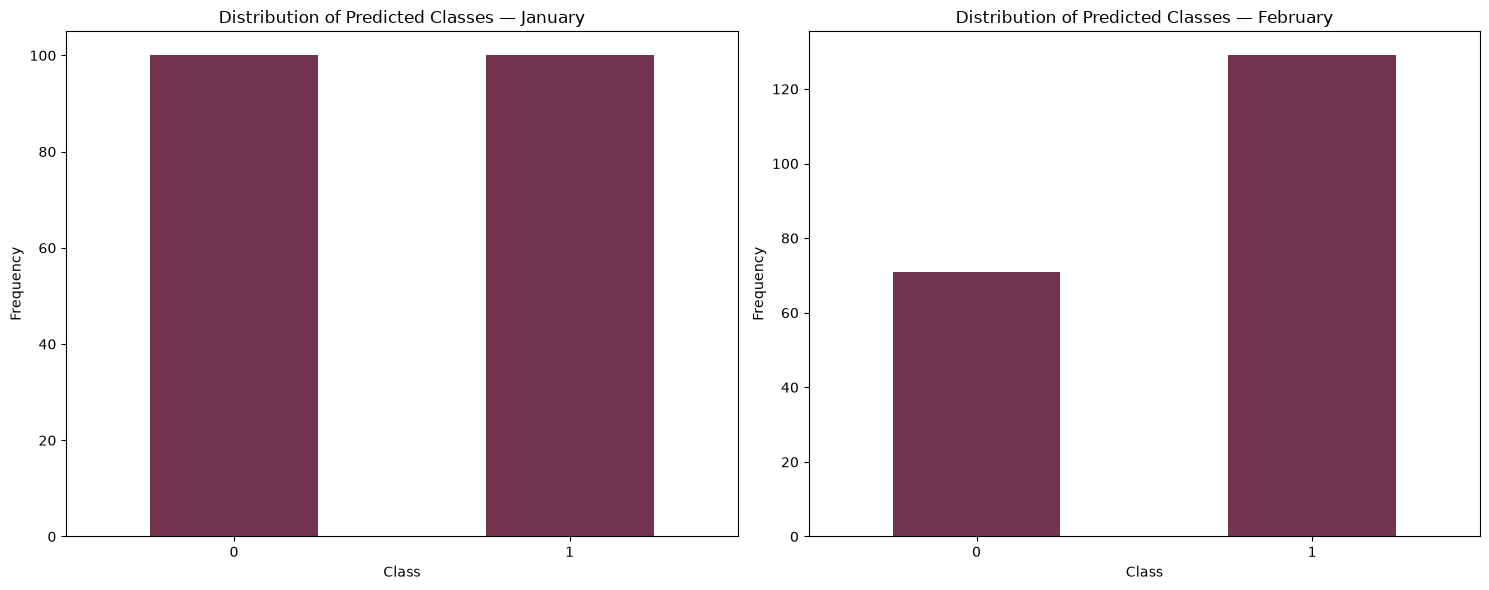

In [194]:
# Plot monthly predicted-class frequencies with consistent styling
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (month, logs) in zip(
    axes,
    (("January", logs_january), ("February", logs_february)),
):
    monthly_counts = logs["target"].value_counts().reindex([0, 1], fill_value=0)
    monthly_counts.plot(kind="bar", ax=ax, color="#73334d")
    ax.set_title(f"Distribution of Predicted Classes — {month}")
    ax.set_xlabel("Class")
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 26. Detect Distributional Change with a Two-Sample KS Test

**Exercise.** Compare the continuous `january_data` and `february_data` samples using `scipy.stats.ks_2samp()`. The test returns a KS statistic—the largest absolute gap between the two empirical cumulative distribution functions—and a p-value.

The null hypothesis is that both independent samples come from the same distribution. We report `"Data drift detected."` when `p_value < 0.05` and `"No data drift detected."` otherwise. 

A non-significant test does not prove the distributions are identical, and a significant result does not by itself demonstrate worse model predictions.

The classical KS test is designed for continuous distributions. Binary class labels contain ties, so a proportion-based test would be more suitable when directly comparing class frequencies. Here we use the separately generated continuous samples.

In [195]:
# Apply the two-sample KS test to continuous monitoring samples
from scipy.stats import ks_2samp

test_statistic, p_value = ks_2samp(january_data, february_data)

if p_value < 0.05:
    print("Data drift detected.")
else:
    print("No data drift detected.")

Data drift detected.


## 27. Feedback Loops: Balanced Accuracy and Drift

**Exercise.** Compare a January balanced-accuracy baseline of 90.0% with February performance calculated from `true_labels_feb` and `predicted_labels_feb`. Balanced accuracy is the mean of class-wise recall; in binary classification it equals `(sensitivity + specificity) / 2`. Scikit-learn returns a value between zero and one, so we multiply by 100 for comparison with the January percentage.

We separately apply the two-sample KS test to `jan_data_samples` and `feb_data_samples`, defining a drift alert as `p_value < 0.05`. 

A performance decline and a distributional change answer different questions. Neither alert on its own proves the model should be retrained; investigation should include outcome quality, model behavior, clinical impact, and validation of any proposed update.

All monitoring inputs are synthetic and illustrate a feedback-loop decision process rather than actual deployed model performance.

In [196]:
# Compare balanced accuracy and evaluate data drift
# Compare February's balanced accuracy with the illustrative January baseline
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import ks_2samp

balanced_accuracy_jan = 90.0
balanced_accuracy_feb = 100 * balanced_accuracy_score(
    true_labels_feb,
    predicted_labels_feb,
)
print(f"Model Balanced Accuracy In February:\n {balanced_accuracy_feb:.2f}%")
print(
    "\nIs there a decline in accuracy?\n",
    f"{'Yes' if balanced_accuracy_feb < balanced_accuracy_jan else 'No'}"
)

# Test the continuous monitoring samples separately for drift
ks_statistic, p_value = ks_2samp(jan_data_samples, feb_data_samples)
significant_drift = p_value < 0.05
print(f"\nKolmogorov-Smirnov Statistic:\n {ks_statistic:.4f}")
print(f"\nP-value:\n {p_value:.4f}")
print(f"\nIs there significant data drift?\n {'Yes' if significant_drift else 'No'}")

Model Balanced Accuracy In February:
 80.00%

Is there a decline in accuracy?
 Yes

Kolmogorov-Smirnov Statistic:
 0.2900

P-value:
 0.0000

Is there significant data drift?
 Yes


### 27.1. Knowledge Check: Investigate Retraining?

**Question.** Given the February balanced accuracy and the KS drift test, should we consider model adjustments or retraining?

1. Yes, but only due to data drift
2. Yes, but only due to the accuracy drop
3. Yes, because both the accuracy drop and data drift call for investigation
4. No, because performance remains strong and significant drift is absent

Use the results in Section 27:

- If balanced accuracy is below the 90% January baseline and the drift-test p-value is below 0.05, option 3 matches the instructional decision rule. 
- If only one alert occurs, choose option 1 or 2; if neither occurs, choose option 4.

The result is a prompt to investigate, not authorization for automatic retraining. The underlying data here are illustrative, and clinical model changes need independent validation.